In [1]:
import quarters_clean

In [2]:
unemployment_q_df = quarters_clean.pd.read_parquet("../data/quarter_unemployment_values.parquet")

In [3]:
unemployment_q_df

,China,Macedonia,Morocco,Philippines,Serbia,Singapore,South-Africa,Thailand,Paraguay,Year,Month,Quarter
0,NaN,NaN,NaN,NaN,NaN,1.8,NaN,NaN,NaN,1992,None,1
1,NaN,NaN,NaN,NaN,NaN,1.5,NaN,NaN,NaN,1993,None,1
2,NaN,NaN,NaN,NaN,NaN,1.7,NaN,NaN,NaN,1994,None,1
3,NaN,NaN,NaN,NaN,NaN,1.7,NaN,NaN,NaN,1995,None,1
4,NaN,NaN,NaN,NaN,NaN,1.8,NaN,NaN,NaN,1996,None,1
...,...,...,...,...,...,...,...,...,...,...,...,...
129,4.24,16.14,11.9,8.75,9.9,3.3,32.5,1.86,7.17,2020,None,4
130,3.96,15.17,12.3,6.37,9.9,2.7,35.3,1.64,6.81,2021,None,4
131,5.50,13.99,11.8,4.77,9.4,2.0,32.7,1.15,5.80,2022,None,4
132,5.10,10.08,13.0,4.47,9.1,2.0,32.1,0.81,5.23,2023,None,4


In [4]:
quarters_clean.summarize_missing_by_country(unemployment_q_df)

,Missing Count,Missing %
Month,134,100.00
Paraguay,102,76.12
China,91,67.91
Serbia,89,66.42
Thailand,77,57.46
South-Africa,65,48.51
Macedonia,58,43.28
Morocco,39,29.10
Philippines,25,18.66
Singapore,2,1.49


**H1)** The previous output indicates that Paraguay will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [5]:
unemployment_q_df = unemployment_q_df.drop(columns=["Month"])

In [6]:
missing_entries = quarters_clean.get_missing_entries(unemployment_q_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1992,China,NaN
1,1,1992,Macedonia,NaN
2,1,1992,Morocco,NaN
3,1,1992,Paraguay,NaN
4,1,1992,Philippines,NaN


In [8]:
paraguay_missing = quarters_clean.clean_country_missing_entries(missing_entries, "Paraguay")
paraguay_missing

,Quarter,Year,Country,Value
0,1,1992,Paraguay,NaN
1,2,1992,Paraguay,NaN
2,3,1992,Paraguay,NaN
3,4,1992,Paraguay,NaN
4,1,1993,Paraguay,NaN
...,...,...,...,...
97,2,2016,Paraguay,NaN
98,3,2016,Paraguay,NaN
99,4,2016,Paraguay,NaN
100,1,2025,Paraguay,NaN


The previous outputs show us that Paraguay has no values for the unemployment rate index from 1992 to 2016. Consequently, it has values in the range from 2016 to 2024, a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023.

### Let's delete all the data from the beginning until 2016

In [9]:
clean_df1 = unemployment_q_df.copy()

In [10]:
clean_df1 = quarters_clean.filter_by_year(clean_df1, min_year=2016, max_year=2024)
clean_df1

,China,Macedonia,Morocco,Philippines,Serbia,Singapore,South-Africa,Thailand,Paraguay,Year,Quarter
0,3.97,22.95,10.7,5.70,14.6,2.2,27.7,1.21,6.35,2017,1
1,3.89,21.61,10.5,5.50,14.8,2.0,26.7,1.24,7.42,2018,1
2,3.67,17.83,9.1,5.13,12.1,2.2,27.6,0.92,6.91,2019,1
3,3.66,16.18,10.5,17.68,9.7,2.4,30.1,1.03,7.93,2020,1
4,3.86,15.98,12.5,8.73,12.8,2.9,32.6,1.96,8.14,2021,1
5,6.10,14.72,12.1,5.71,10.6,2.2,34.5,1.53,8.27,2022,1
6,5.30,13.26,12.9,4.48,10.0,1.8,32.9,1.05,6.51,2023,1
7,5.20,12.87,13.7,4.05,9.4,2.1,32.9,1.01,6.90,2024,1
8,3.95,22.58,9.3,5.60,11.8,NaN,27.7,1.22,7.26,2017,2
9,3.83,21.14,9.1,5.40,11.9,2.0,27.2,1.07,5.95,2018,2


In [11]:
clean_df1 = clean_df1.sort_values(by=['Year', 'Quarter'])
clean_df1

,China,Macedonia,Morocco,Philippines,Serbia,Singapore,South-Africa,Thailand,Paraguay,Year,Quarter
0,3.97,22.95,10.7,5.70,14.6,2.2,27.7,1.21,6.35,2017,1
8,3.95,22.58,9.3,5.60,11.8,NaN,27.7,1.22,7.26,2017,2
16,3.95,22.14,10.6,5.00,12.9,2.1,27.7,1.19,5.53,2017,3
24,3.90,21.86,10.6,5.30,14.7,2.1,26.7,1.12,5.20,2017,4
1,3.89,21.61,10.5,5.50,14.8,2.0,26.7,1.24,7.42,2018,1
9,3.83,21.14,9.1,5.40,11.9,2.0,27.2,1.07,5.95,2018,2
17,3.82,20.79,10.0,5.06,11.3,2.1,27.5,0.96,5.98,2018,3
25,3.80,19.40,9.5,5.24,12.9,2.2,27.1,0.93,5.60,2018,4
2,3.67,17.83,9.1,5.13,12.1,2.2,27.6,0.92,6.91,2019,1
10,3.61,17.47,8.1,5.36,10.3,2.2,29.0,0.98,7.44,2019,2


In [12]:
clean_df1 = clean_df1.reset_index(drop=True)
clean_df1

,China,Macedonia,Morocco,Philippines,Serbia,Singapore,South-Africa,Thailand,Paraguay,Year,Quarter
0,3.97,22.95,10.7,5.70,14.6,2.2,27.7,1.21,6.35,2017,1
1,3.95,22.58,9.3,5.60,11.8,NaN,27.7,1.22,7.26,2017,2
2,3.95,22.14,10.6,5.00,12.9,2.1,27.7,1.19,5.53,2017,3
3,3.90,21.86,10.6,5.30,14.7,2.1,26.7,1.12,5.20,2017,4
4,3.89,21.61,10.5,5.50,14.8,2.0,26.7,1.24,7.42,2018,1
5,3.83,21.14,9.1,5.40,11.9,2.0,27.2,1.07,5.95,2018,2
6,3.82,20.79,10.0,5.06,11.3,2.1,27.5,0.96,5.98,2018,3
7,3.80,19.40,9.5,5.24,12.9,2.2,27.1,0.93,5.60,2018,4
8,3.67,17.83,9.1,5.13,12.1,2.2,27.6,0.92,6.91,2019,1
9,3.61,17.47,8.1,5.36,10.3,2.2,29.0,0.98,7.44,2019,2


In [13]:
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Singapore,2,6.25
China,0,0.00
Macedonia,0,0.00
Philippines,0,0.00
Morocco,0,0.00
Serbia,0,0.00
South-Africa,0,0.00
Thailand,0,0.00
Paraguay,0,0.00


In [14]:
clean_df1["Singapore"] = clean_df1["Singapore"].ffill()
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
China,0,0.0
Macedonia,0,0.0
Morocco,0,0.0
Philippines,0,0.0
Serbia,0,0.0
Singapore,0,0.0
South-Africa,0,0.0
Thailand,0,0.0
Paraguay,0,0.0


In [15]:
clean_df1 = quarters_clean.average_by_year(clean_df1)

   Year   China  Macedonia  Morocco  Philippines  Serbia  Singapore  \
0  2017  3.9425    22.3825   10.300       5.4000  13.500      2.150   
1  2018  3.8350    20.7350    9.775       5.3000  12.725      2.075   
2  2019  3.6275    17.2575    8.950       5.0850  10.400      2.250   
3  2020  3.9825    16.4000   11.850      11.2800   8.975      3.025   
4  2021  3.9100    15.6850   12.350       7.3425  11.125      2.800   

   South-Africa  Thailand  Paraguay  
0        27.450     1.185    6.0850  
1        27.125     1.050    6.2375  
2        28.700     0.980    6.5700  
3        29.175     1.685    7.7100  
4        34.300     1.935    7.5075  


In [16]:
clean_df1

,Year,China,Macedonia,Morocco,Philippines,Serbia,Singapore,South-Africa,Thailand,Paraguay
0,2017,3.9425,22.3825,10.300,5.4000,13.500,2.150,27.450,1.1850,6.0850
1,2018,3.8350,20.7350,9.775,5.3000,12.725,2.075,27.125,1.0500,6.2375
2,2019,3.6275,17.2575,8.950,5.0850,10.400,2.250,28.700,0.9800,6.5700
3,2020,3.9825,16.4000,11.850,11.2800,8.975,3.025,29.175,1.6850,7.7100
4,2021,3.9100,15.6850,12.350,7.3425,11.125,2.800,34.300,1.9350,7.5075
5,2022,5.6500,14.3600,11.625,5.0575,9.475,2.075,33.500,1.3200,6.7275
6,2023,5.1500,12.3200,12.950,4.4975,9.425,1.925,32.375,0.9775,5.8850
7,2024,5.1000,12.3975,13.425,4.2450,8.575,1.975,32.600,0.9950,5.8050


### For month values now

In [17]:
unemployment_m_df = quarters_clean.pd.read_parquet("../data/month_unemployment_values.parquet")

In [18]:
unemployment_m_df

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,South-Korea,Spain,Sweden,Switzerland,Turkey,USA,United-Kingdom,Year,Month,Quarter
0,6.25,NaN,NaN,NaN,NaN,9.3,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,6.1,5.6,1978,Apr,2
1,6.46,NaN,NaN,NaN,NaN,8.6,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5.8,5.3,1979,Apr,2
2,6.15,NaN,NaN,NaN,NaN,8.3,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,6.9,6.1,1980,Apr,2
3,5.58,NaN,NaN,NaN,NaN,7.7,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,7.2,9.4,1981,Apr,2
4,6.40,NaN,NaN,NaN,NaN,10.5,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,9.3,10.5,1982,Apr,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
782,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.8,2.3,1967,Sep,3
783,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.4,2.3,1968,Sep,3
784,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,3.7,2.3,1969,Sep,3
785,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5.4,2.5,1970,Sep,3


In [20]:
quarters_clean.summarize_missing_by_country(unemployment_m_df)

,Missing Count,Missing %
India,700,88.95
Israel,629,79.92
New-Zealand,629,79.92
Brazil,627,79.67
Malaysia,604,76.75
Switzerland,604,76.75
Russia,574,72.94
Germany,565,71.79
Mexico,544,69.12
Turkey,542,68.87


**H1)** The previous output indicates that India will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [23]:
missing_entries = quarters_clean.get_missing_entries(unemployment_m_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1960,Australia,NaN
1,1,1960,Australia,NaN
2,1,1960,Australia,NaN
3,1,1960,Austria,NaN
4,1,1960,Austria,NaN


In [25]:
india_missing = quarters_clean.clean_country_missing_entries(missing_entries, "India")
india_missing.tail(30)

,Quarter,Year,Country,Value
670,4,2015,India,NaN
671,4,2015,India,NaN
672,2,2023,India,NaN
673,2,2023,India,NaN
674,2,2023,India,NaN
675,3,2023,India,NaN
676,3,2023,India,NaN
677,3,2023,India,NaN
678,4,2023,India,NaN
679,4,2023,India,NaN


Looking at the page from which the values ​​were extracted, it could be seen that India has defined values ​​in the range from 2016 to 2023 inclusive of both years.

### Let's delete all the data from the beginning until 2015

In [26]:
clean_df2 = unemployment_m_df.copy()

In [27]:
clean_df2 = quarters_clean.filter_by_year(clean_df2, min_year=2015, max_year=2023)
clean_df2

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,South-Korea,Spain,Sweden,Switzerland,Turkey,USA,United-Kingdom,Year,Month,Quarter
0,5.67,6.2,8.1,11.3,9.5,7.6,6.61,9.02,13.6,12.3,...,3.9,20.6,7.4,4.8,9.1,5.0,4.9,2016,Apr,2
1,5.65,5.8,7.3,13.7,7.6,6.8,7.08,8.79,11.5,11.2,...,4.2,17.9,7.3,4.6,10.5,4.4,4.4,2017,Apr,2
2,5.59,5.2,6.3,13.0,6.7,6.0,6.99,9.32,8.6,7.6,...,4.1,15.9,6.9,4.8,9.3,3.9,4.2,2018,Apr,2
3,5.27,5.0,5.5,12.6,5.5,5.9,7.10,10.16,6.7,7.1,...,4.4,14.3,6.9,4.3,12.8,3.6,3.8,2019,Apr,2
4,6.38,6.1,4.8,12.7,7.1,14.0,9.00,19.81,7.7,7.1,...,4.2,15.3,8.5,4.5,12.8,14.8,4.1,2020,Apr,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,5.09,4.3,5.3,11.9,4.6,5.1,7.34,10.29,5.7,5.8,...,3.1,13.9,6.1,4.5,14.0,3.5,3.8,2019,Sep,3
92,6.72,6.0,6.4,14.9,5.8,8.4,12.35,15.77,7.6,7.7,...,3.6,16.4,8.4,5.2,12.4,7.8,5.2,2020,Sep,3
93,4.56,4.6,6.3,12.7,4.3,6.5,8.41,11.96,6.4,5.3,...,2.7,14.4,8.4,4.9,11.1,4.7,4.3,2021,Sep,3
94,3.48,4.9,5.6,8.7,3.4,4.8,8.04,10.75,6.4,5.2,...,2.4,13.0,6.5,4.0,9.9,3.5,3.8,2022,Sep,3


In [28]:
quarters_clean.summarize_missing_by_country(clean_df2)

,Missing Count,Missing %
New-Zealand,64,66.67
India,9,9.38
Turkey,1,1.04
Australia,0,0.00
Bulgaria,0,0.00
Austria,0,0.00
Belgium,0,0.00
Brazil,0,0.00
Croatia,0,0.00
Cyprus,0,0.00


Back to the page where the values ​​were extracted from, it could be seen that New Zealand has defined values ​​in the range from 1986 to 2023, both years included. The NaN values ​​are probably due to the fact that they are not defined for a certain month. It will be filled in forward and then the values ​​will be added per year, taking into account the average.

In [29]:
clean_df2["New-Zealand"] = clean_df2["New-Zealand"].ffill()
clean_df2["India"] = clean_df2["India"].ffill()
clean_df2["Turkey"] = clean_df2["Turkey"].ffill()

In [30]:
quarters_clean.summarize_missing_by_country(clean_df2)

,Missing Count,Missing %
New-Zealand,16,16.67
Australia,0,0.00
Belgium,0,0.00
Austria,0,0.00
Bulgaria,0,0.00
Canada,0,0.00
Chile,0,0.00
Brazil,0,0.00
Croatia,0,0.00
Cyprus,0,0.00


In [31]:
clean_df2["New-Zealand"] = clean_df2["New-Zealand"].bfill()

In [32]:
quarters_clean.summarize_missing_by_country(clean_df2)

,Missing Count,Missing %
Australia,0,0.0
Austria,0,0.0
Belgium,0,0.0
Brazil,0,0.0
Bulgaria,0,0.0
Canada,0,0.0
Chile,0,0.0
Colombia,0,0.0
Croatia,0,0.0
Cyprus,0,0.0


In [33]:
clean_df2 = clean_df2.sort_values(by=['Year', 'Quarter'])
clean_df2

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,South-Korea,Spain,Sweden,Switzerland,Turkey,USA,United-Kingdom,Year,Month,Quarter
24,6.17,7.6,8.3,10.3,9.6,7.7,6.05,10.05,16.0,14.4,...,4.9,21.1,7.7,5.4,11.0,4.9,5.1,2016,Feb,1
32,6.49,7.3,8.6,9.6,9.4,7.7,5.92,11.79,16.4,13.9,...,3.7,21.0,7.6,5.3,11.5,4.9,5.1,2016,Jan,1
56,6.00,6.9,8.1,11.0,9.7,7.8,6.49,10.14,15.3,13.8,...,4.3,20.9,7.9,5.3,10.1,5.0,5.0,2016,Mar,1
0,5.67,6.2,8.1,11.3,9.5,7.6,6.61,9.02,13.6,12.3,...,3.9,20.6,7.4,4.8,9.1,5.0,4.9,2016,Apr,2
48,5.54,6.3,7.8,11.4,8.7,6.5,7.02,8.89,11.8,12.4,...,3.6,19.4,7.7,4.6,10.1,4.9,4.9,2016,June,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47,3.64,5.4,5.6,7.9,4.2,5.9,8.77,9.57,5.7,6.1,...,2.7,11.7,6.2,4.1,9.7,3.5,4.3,2023,Jul,3
95,3.45,5.1,5.6,7.7,3.9,5.2,8.91,9.25,5.6,4.6,...,2.3,12.1,7.7,4.4,8.9,3.8,4.0,2023,Sep,3
23,3.78,5.4,5.5,7.4,4.4,5.3,8.48,10.01,6.0,6.1,...,3.3,11.7,7.7,4.1,8.9,3.7,4.1,2023,Dec,4
79,3.63,4.7,5.4,7.5,4.2,5.3,8.73,9.01,5.9,6.0,...,2.3,11.7,7.1,3.9,8.8,3.7,3.9,2023,Nov,4


In [34]:
clean_df2 = clean_df2.reset_index(drop=True)
clean_df2

,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,Cyprus,...,South-Korea,Spain,Sweden,Switzerland,Turkey,USA,United-Kingdom,Year,Month,Quarter
0,6.17,7.6,8.3,10.3,9.6,7.7,6.05,10.05,16.0,14.4,...,4.9,21.1,7.7,5.4,11.0,4.9,5.1,2016,Feb,1
1,6.49,7.3,8.6,9.6,9.4,7.7,5.92,11.79,16.4,13.9,...,3.7,21.0,7.6,5.3,11.5,4.9,5.1,2016,Jan,1
2,6.00,6.9,8.1,11.0,9.7,7.8,6.49,10.14,15.3,13.8,...,4.3,20.9,7.9,5.3,10.1,5.0,5.0,2016,Mar,1
3,5.67,6.2,8.1,11.3,9.5,7.6,6.61,9.02,13.6,12.3,...,3.9,20.6,7.4,4.8,9.1,5.0,4.9,2016,Apr,2
4,5.54,6.3,7.8,11.4,8.7,6.5,7.02,8.89,11.8,12.4,...,3.6,19.4,7.7,4.6,10.1,4.9,4.9,2016,June,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,3.64,5.4,5.6,7.9,4.2,5.9,8.77,9.57,5.7,6.1,...,2.7,11.7,6.2,4.1,9.7,3.5,4.3,2023,Jul,3
92,3.45,5.1,5.6,7.7,3.9,5.2,8.91,9.25,5.6,4.6,...,2.3,12.1,7.7,4.4,8.9,3.8,4.0,2023,Sep,3
93,3.78,5.4,5.5,7.4,4.4,5.3,8.48,10.01,6.0,6.1,...,3.3,11.7,7.7,4.1,8.9,3.7,4.1,2023,Dec,4
94,3.63,4.7,5.4,7.5,4.2,5.3,8.73,9.01,5.9,6.0,...,2.3,11.7,7.1,3.9,8.8,3.7,3.9,2023,Nov,4


In [35]:
clean_df2 = quarters_clean.average_by_year(clean_df2)

   Year  Australia   Austria   Belgium     Brazil  Bulgaria    Canada  \
0  2016   5.713333  6.450000  7.850000  11.366667  8.583333  7.025000   
1  2017   5.606667  5.925000  7.100000  12.875000  7.166667  6.425000   
2  2018   5.306667  5.208333  5.958333  12.366667  6.216667  5.841667   
3  2019   5.165000  4.841667  5.366667  12.033333  5.191667  5.691667   
4  2020   6.441667  6.025000  5.541667  13.475000  6.058333  9.691667   

       Chile   Colombia    Croatia  ...    Russia  Slovakia  Slovenia  \
0   6.647500   9.226667  13.275000  ...  5.537500  9.658333  8.008333   
1   6.935000   9.295833  10.941667  ...  5.205000  8.083333  6.575000   
2   7.334167   9.529167   8.300000  ...  4.802500  6.508333  5.125000   
3   7.216667  10.370833   6.566667  ...  4.595833  5.716667  4.441667   
4  10.574167  16.071667   7.650000  ...  5.765000  6.658333  4.983333   

   South-Korea      Spain    Sweden  Switzerland     Turkey       USA  \
0     3.708333  19.650000  7.058333     4.916667 

In [36]:
clean_df2

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,Russia,Slovakia,Slovenia,South-Korea,Spain,Sweden,Switzerland,Turkey,USA,United-Kingdom
0,2016,5.713333,6.450000,7.850000,11.366667,8.583333,7.025000,6.647500,9.226667,13.275000,...,5.537500,9.658333,8.008333,3.708333,19.650000,7.058333,4.916667,10.908333,4.866667,4.891667
1,2017,5.606667,5.925000,7.100000,12.875000,7.166667,6.425000,6.935000,9.295833,10.941667,...,5.205000,8.083333,6.575000,3.700000,17.233333,6.783333,4.800000,10.925000,4.350000,4.383333
2,2018,5.306667,5.208333,5.958333,12.366667,6.216667,5.841667,7.334167,9.529167,8.300000,...,4.802500,6.508333,5.125000,3.833333,15.266667,6.433333,4.708333,10.900000,3.891667,4.075000
3,2019,5.165000,4.841667,5.366667,12.033333,5.191667,5.691667,7.216667,10.370833,6.566667,...,4.595833,5.716667,4.441667,3.691667,14.108333,6.908333,4.391667,13.733333,3.675000,3.850000
4,2020,6.441667,6.025000,5.541667,13.475000,6.058333,9.691667,10.574167,16.071667,7.650000,...,5.765000,6.658333,4.983333,3.916667,15.533333,8.483333,4.800000,13.141667,8.108333,4.600000
5,2021,5.138333,6.200000,6.275000,13.500000,5.175000,7.541667,9.112500,13.810833,7.500000,...,4.820000,6.825000,4.775000,3.675000,14.933333,8.891667,5.008333,12.175000,5.358333,4.541667
6,2022,3.725833,4.758333,5.575000,9.508333,4.158333,5.300000,7.800000,11.218333,6.725000,...,3.938333,6.150000,4.025000,2.883333,13.033333,7.483333,4.125000,10.483333,3.641667,3.783333
7,2023,3.686667,5.108333,5.525000,8.041667,4.341667,5.425000,8.642500,10.164167,6.066667,...,3.152500,5.850000,3.658333,2.708333,12.191667,7.666667,4.041667,9.391667,3.625000,4.066667


In [37]:
clean_df1

,Year,China,Macedonia,Morocco,Philippines,Serbia,Singapore,South-Africa,Thailand,Paraguay
0,2017,3.9425,22.3825,10.300,5.4000,13.500,2.150,27.450,1.1850,6.0850
1,2018,3.8350,20.7350,9.775,5.3000,12.725,2.075,27.125,1.0500,6.2375
2,2019,3.6275,17.2575,8.950,5.0850,10.400,2.250,28.700,0.9800,6.5700
3,2020,3.9825,16.4000,11.850,11.2800,8.975,3.025,29.175,1.6850,7.7100
4,2021,3.9100,15.6850,12.350,7.3425,11.125,2.800,34.300,1.9350,7.5075
5,2022,5.6500,14.3600,11.625,5.0575,9.475,2.075,33.500,1.3200,6.7275
6,2023,5.1500,12.3200,12.950,4.4975,9.425,1.925,32.375,0.9775,5.8850
7,2024,5.1000,12.3975,13.425,4.2450,8.575,1.975,32.600,0.9950,5.8050


In [39]:
df_merged = quarters_clean.pd.merge(clean_df1,clean_df2, on='Year', how='outer')

In [41]:
quarters_clean.summarize_missing_by_country(df_merged)

,Missing Count,Missing %
China,1,11.11
Macedonia,1,11.11
Morocco,1,11.11
Philippines,1,11.11
Serbia,1,11.11
Singapore,1,11.11
South-Africa,1,11.11
Thailand,1,11.11
Paraguay,1,11.11
Australia,1,11.11


In [42]:
df_merged = df_merged.ffill()
df_merged = df_merged.bfill()

In [43]:
quarters_clean.summarize_missing_by_country(df_merged)

,Missing Count,Missing %
China,0,0.0
Macedonia,0,0.0
Morocco,0,0.0
Philippines,0,0.0
Serbia,0,0.0
Singapore,0,0.0
South-Africa,0,0.0
Thailand,0,0.0
Paraguay,0,0.0
Australia,0,0.0


In [44]:
df_merged

,Year,China,Macedonia,Morocco,Philippines,Serbia,Singapore,South-Africa,Thailand,Paraguay,...,Russia,Slovakia,Slovenia,South-Korea,Spain,Sweden,Switzerland,Turkey,USA,United-Kingdom
0,2016,3.9425,22.3825,10.300,5.4000,13.500,2.150,27.450,1.1850,6.0850,...,5.537500,9.658333,8.008333,3.708333,19.650000,7.058333,4.916667,10.908333,4.866667,4.891667
1,2017,3.9425,22.3825,10.300,5.4000,13.500,2.150,27.450,1.1850,6.0850,...,5.205000,8.083333,6.575000,3.700000,17.233333,6.783333,4.800000,10.925000,4.350000,4.383333
2,2018,3.8350,20.7350,9.775,5.3000,12.725,2.075,27.125,1.0500,6.2375,...,4.802500,6.508333,5.125000,3.833333,15.266667,6.433333,4.708333,10.900000,3.891667,4.075000
3,2019,3.6275,17.2575,8.950,5.0850,10.400,2.250,28.700,0.9800,6.5700,...,4.595833,5.716667,4.441667,3.691667,14.108333,6.908333,4.391667,13.733333,3.675000,3.850000
4,2020,3.9825,16.4000,11.850,11.2800,8.975,3.025,29.175,1.6850,7.7100,...,5.765000,6.658333,4.983333,3.916667,15.533333,8.483333,4.800000,13.141667,8.108333,4.600000
5,2021,3.9100,15.6850,12.350,7.3425,11.125,2.800,34.300,1.9350,7.5075,...,4.820000,6.825000,4.775000,3.675000,14.933333,8.891667,5.008333,12.175000,5.358333,4.541667
6,2022,5.6500,14.3600,11.625,5.0575,9.475,2.075,33.500,1.3200,6.7275,...,3.938333,6.150000,4.025000,2.883333,13.033333,7.483333,4.125000,10.483333,3.641667,3.783333
7,2023,5.1500,12.3200,12.950,4.4975,9.425,1.925,32.375,0.9775,5.8850,...,3.152500,5.850000,3.658333,2.708333,12.191667,7.666667,4.041667,9.391667,3.625000,4.066667
8,2024,5.1000,12.3975,13.425,4.2450,8.575,1.975,32.600,0.9950,5.8050,...,3.152500,5.850000,3.658333,2.708333,12.191667,7.666667,4.041667,9.391667,3.625000,4.066667


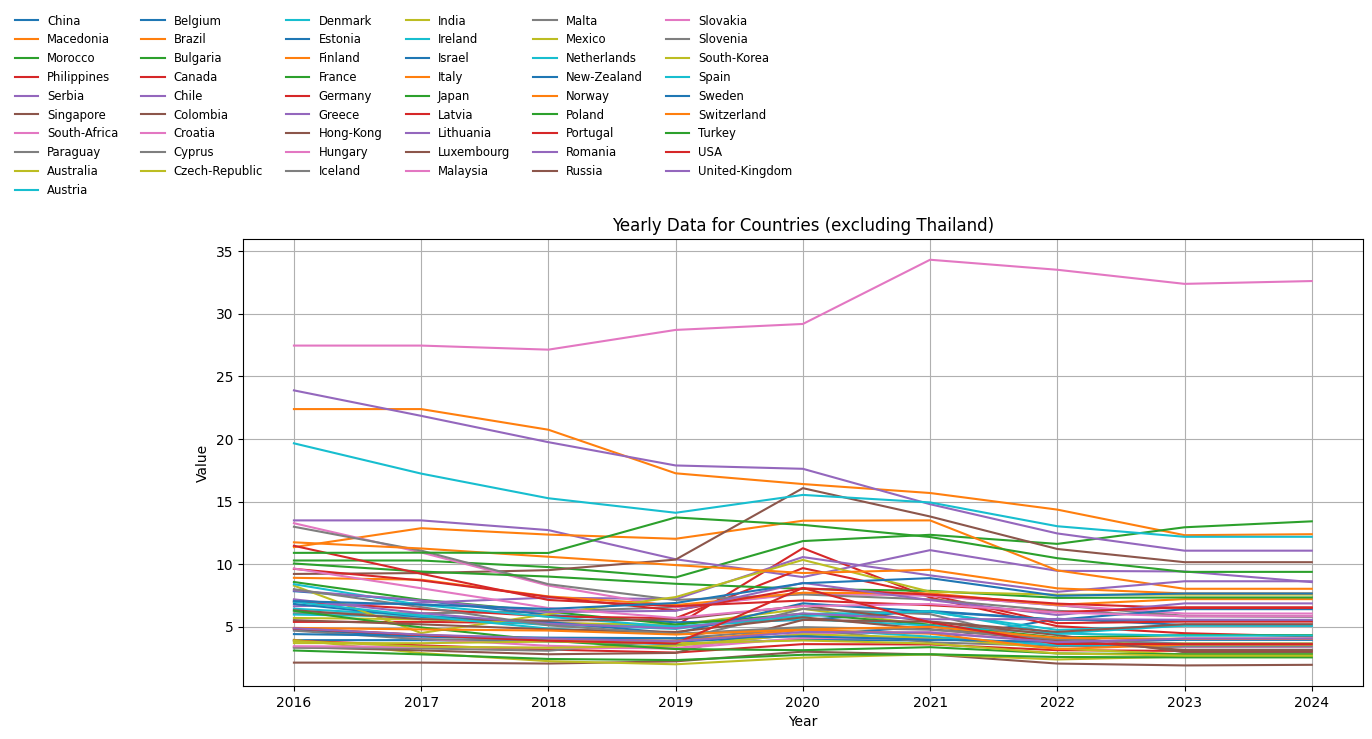

In [45]:
quarters_clean.plot_countries(df_merged, exclude_country='Thailand', legend_columns=6)

In [46]:
df_merged.to_parquet("../data/clean_unemployment_rate_index.parquet", index=False)